# Task 2 — Decision Trees

**Seed:** last 4 digits of student ID = **3039**

In [1]:
import sys

import numpy
import pandas
import sklearn

print(sys.version.split()[0], numpy.__version__, pandas.__version__, sklearn.__version__)

3.12.3 2.0.2 2.3.3 1.6.1


In [2]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

SEED = 3039

data = pd.read_csv("data/heart_disease.csv")
feature_names = [c for c in data.columns if c != "disease"]
X, y = data[feature_names].to_numpy(), data["disease"].to_numpy()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=SEED
)
print(data.shape, round(y.mean(), 3), X_train.shape, X_test.shape)

(297, 14) 0.461 (207, 13) (90, 13)


## Part 1

### 1. Parent entropy

12 patients: 6 with disease (p=1), 6 without (p=0). Both proportions are 0.5.

H = −(0.5 · log2(0.5) + 0.5 · log2(0.5))
  = −(0.5 · (−1) + 0.5 · (−1))
  = 1.0 bit

### 2. Information gain and root

**age_55_plus**

- `age_55_plus = 1`: 6 patients (5 with disease, 1 without)
  H = -(5/6 · log2(5/6) + 1/6 · log2(1/6)) = 0.650
- `age_55_plus = 0`: 6 patients (1 with disease, 5 without)
  H = -(1/6 · log2(1/6) + 5/6 · log2(5/6)) = 0.650
- Weighted H = (6/12) · 0.650 + (6/12) · 0.650 = 0.650
- **Gain = 1.0 - 0.650 = 0.350**


**exercise_angina**

- `exercise_angina = 1`: 4 patients (all 4 with disease)
  H = 0 (pure node)
- `exercise_angina = 0`: 8 patients (2 with disease, 6 without)
  H = -(2/8 · log2(2/8) + 6/8 · log2(6/8)) = 0.811
- Weighted H = (4/12) · 0 + (8/12) · 0.811 = 0.541
- **Gain = 1.0 - 0.541 = 0.459**


**male** 

- `male = 1`: 6 patients (3 with disease, 3 without)
- `male = 0`: 6 patients (3 with disease, 3 without)
- Weighted H = (6/12) · 1.0 + (6/12) · 1.0 = 1.0
- **Gain = 1.0- 1.0 = 0.000**


**high_bp**

- `high_bp = 1`: 6 patients (4 with disease, 2 without)
  H = -(4/6 · log2(4/6) + 2/6 · log2(2/6)) = 0.918
- `high_bp = 0`: 6 patients (2 with disease, 4 without)
  H = 0.918 (symmetric)
- Weighted H = 0.918
- **Gain = 1.0 - 0.918 = 0.082**


**Summary of gains:**

| Feature | Gain |
| --- | --- |
| age_55_plus | 0.350 |
| exercise_angina | **0.459** |
| male | 0.000 |
| high_bp | 0.082 |

**Root:** `exercise_angina` - it has the highest information gain (0.459)

### 3. One level down

After splitting on exercise_angina, the branch exercise_angina = 1 is pure because all 4 patients have disease.

The impuren branch is exercise_angina =0. It contains 8 patients: 2 with disease and 6 without.

H = -(2/8 · log2(2/8) + 6/8 · log2(6/8)) = 0.811


**age_55_plus**
- `age_55_plus = 1`: 2 patients (1 with disease, 1 without)
- `age_55_plus = 1`: 6 patients (1 with disease, 5 without)
  H = -(1/6 · log2(1/6) + 5/6 · log2(5/6)) = 0.650
- Weighted H = (2/8) · 1.000 + (6/8) · 0.650 = 0.738
- **Gain = 0.811 - 0.738 = 0.074**


**male**

- `male = 1`: 3 patients (0 with disease, 3 without) -> H = 0.000 (pure)
- `male = 0`: 5 patients (2with disease, 3 without)
  H = -(2/5 · log2(2/5) + 3/5 · log2(3/5)) = 0.971
- Weighted H = (3/8) · 0.000 + (5/8) · 0.971 = 0.607
- **Gain = 0.811 - 0.607 = 0.204**


**high_bp**

- `high_bp = 1`: 3 patients (1 with disease, 2 without) -> H = 0.918
- `high_bp = 0`: 5 patients (1 with disease, 4 without) -> H = 0.722
- Weithed H = (3/8) · 0.918 + (5/8) · 0.722 = 0.796
- **Gain  = 0.811 - 0.796 = 0.016**


**Summary - gains in branch vas gains at root:**

| Feature | Gain in branch | Gain at root |
| --- | --- | --- |
| age_55_plus | 0.074 | 0.350 |
| **male** | **0.204** | **0.000** |
| high_bp | 0.016 | 0.082 |


**Chosen second featre:** `male` - highest gain in this branch (0.204).

At the root, male had an information gain of 0, but inside the exercise_angina = 0 branch its gain is 0.204. A feature can be useless at the root but useful inside a branch because after the first split we are working with a different subset of the data.

In [ ]:
#Task 2
#entropy
import numpy as np
def entropy(y):
    """Entropy in bits of an array of integer class labels."""
    if len(y) == 0:
        return 0.0
    _, counts = np.unique(y, return_counts=True)
    p = counts / len(y)
    return -np.sum(p * np.log2(p))

print("Pure (all 1s):", entropy(np.array([1, 1, 1, 1])))
print("Pure (all 0s):", entropy(np.array([0, 0, 0, 0])))
print("50/50:", entropy(np.array([0, 0, 1, 1])))
print("Toy table:", entropy(toy["disease"].values))

Pure (all 1s): -0.0
Pure (all 0s): -0.0
50/50: 1.0
Toy table: 1.0


In [ ]:
#information gain
def information_gain(y, left):
    """Entropy of y minus the size-weighted entropy of y[left] and y[~left]; left is a boolean mask."""
    n = len(y)
    n_left = left.sum()
    n_right = n - n_left
    if n_left == 0 or n_right == 0:
        return 0.0
    return entropy(y) - (n_left / n) * entropy(y[left]) - (n_right / n) * entropy(y[~left])


y_toy = toy["disease"].values
for col in ["age_55_plus", "exercise_angina", "male", "high_bp"]:
    left = toy[col].values == 1
    gain = information_gain(y_toy, left)
    print(f"{col}: gain = {gain:.4f}")

age_55_plus: gain = 0.3500
exercise_angina: gain = 0.4591
male: gain = 0.0000
high_bp: gain = 0.0817


In [10]:
#best split
def best_split(X, y, min_samples_leaf=1):
    """Return (feature_index, threshold, gain) of the best split, or None if no valid split exists."""
    best_gain = -1.0
    best_feature = None
    best_threshold = None
    n_features = X.shape[1]

    for f in range(n_features):
        values = np.unique(X[:, f])
        if len(values) < 2:
            continue
        thresholds = (values[:-1] + values[1:]) / 2
        for t in thresholds:
            left = X[:, f] <= t
            n_left = left.sum()
            n_right = len(y) - n_left
            if n_left < min_samples_leaf or n_right < min_samples_leaf:
                continue
            gain = information_gain(y, left)
            if gain > best_gain:
                best_gain = gain
                best_feature = f
                best_threshold = t

    if best_feature is None:
        return None
    return best_feature, best_threshold, best_gain


toy_X = toy[["age_55_plus", "exercise_angina", "male", "high_bp"]].values
toy_y = toy["disease"].values
result = best_split(toy_X, toy_y)
print("Toy best split:", result)

Toy best split: (1, np.float64(0.5), np.float64(0.4591479170272448))


In [11]:
result_real = best_split(X_train, y_train)
print("Real best split:", result_real)
print("Feature:", feature_names[result_real[0]])
print("Threshold:", result_real[1])
print("Gain:", result_real[2])

Real best split: (11, np.float64(0.5), np.float64(0.24114650717204555))
Feature: ca
Threshold: 0.5
Gain: 0.24114650717204555


In [12]:
from sklearn.tree import DecisionTreeClassifier

ref = DecisionTreeClassifier(criterion="entropy", max_depth=1, random_state=SEED).fit(X_train, y_train)
print(f"sklearn: {feature_names[ref.tree_.feature[0]]}, threshold = {ref.tree_.threshold[0]:.4f}")

sklearn: ca, threshold = 0.5000


In [13]:
#build tree
def build_tree(X, y, max_depth=None, min_samples_leaf=1, depth=0):
    """Grow a tree recursively and return it as nested dicts."""

    if len(np.unique(y)) == 1:
        return {"leaf": True, "prediction": int(y[0]), "n": len(y)}
    
    if max_depth is not None and depth >= max_depth:
        counts = np.bincount(y)
        return {"leaf": True, "prediction": int(np.argmax(counts)), "n": len(y)}
    
    split = best_split(X, y, min_samples_leaf)
    if split is None:
        counts = np.bincount(y)
        return {"leaf": True, "prediction": int(np.argmax(counts)), "n": len(y)}
    
    
    
    feature, threshold, gain = split
    left_mask = X[:, feature] <= threshold
    left = build_tree(X[left_mask], y[left_mask], max_depth, min_samples_leaf, depth + 1)
    right = build_tree(X[~left_mask], y[~left_mask], max_depth, min_samples_leaf, depth + 1)
    
    return {
        "leaf": False,
        "feature": feature,
        "threshold": threshold,
        "gain": gain,
        "n": len(y),
        "left": left,
        "right": right,
    }

In [14]:
#predict tree
def predict_tree(tree, X):
    """Return one predicted label per row of X."""
    predictions = []
    for row in X:
        node = tree
        while not node["leaf"]:
            if row[node["feature"]] <= node["threshold"]:
                node = node["left"]
            else:
                node = node["right"]
        predictions.append(node["prediction"])
    return np.array(predictions)

In [15]:
toy_X = toy[["age_55_plus", "exercise_angina", "male", "high_bp"]].values
toy_y = toy["disease"].values

tree_toy = build_tree(toy_X, toy_y, max_depth=3)
print("Tree built on toy")
print("Root feature:", tree_toy["feature"], "=", ["age_55_plus", "exercise_angina", "male", "high_bp"][tree_toy["feature"]])
print("Root threshold:", tree_toy["threshold"])

preds_toy = predict_tree(tree_toy, toy_X)
print("Predictions:", preds_toy)
print("Actual:     ", toy_y)
print("Accuracy on toy:", (preds_toy == toy_y).mean())


Tree built on toy
Root feature: 1 = exercise_angina
Root threshold: 0.5
Predictions: [1 1 1 1 1 0 0 0 0 0 0 0]
Actual:      [1 1 1 1 1 1 0 0 0 0 0 0]
Accuracy on toy: 0.9166666666666666


In [16]:
tree_real = build_tree(X_train, y_train, max_depth=3)
preds_real = predict_tree(tree_real, X_train)
print("Train accuracy (my tree, depth=3):", (preds_real == y_train).mean())

preds_test = predict_tree(tree_real, X_test)
print("Test accuracy (my tree, depth=3):", (preds_test == y_test).mean())

Train accuracy (my tree, depth=3): 0.8405797101449275
Test accuracy (my tree, depth=3): 0.8111111111111111


In [17]:
from sklearn.tree import DecisionTreeClassifier

print(f"{'Depth':<10} {'Agreement':<12}")
print("-" * 25)

for depth in [1, 2, 3, 4, 5, None]:
    my_tree = build_tree(X_train, y_train, max_depth=depth)
    my_preds = predict_tree(my_tree, X_test)
    
    sk_tree = DecisionTreeClassifier(
        criterion="entropy", max_depth=depth, random_state=SEED
    ).fit(X_train, y_train)
    sk_preds = sk_tree.predict(X_test)
    
    agreement = (my_preds == sk_preds).mean()
    print(f"{str(depth):<10} {agreement:<12.4f}")

Depth      Agreement   
-------------------------
1          1.0000      
2          1.0000      
3          1.0000      
4          1.0000      
5          0.9667      
None       0.9667      


In [19]:
#Task 3
#3a
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.tree import DecisionTreeClassifier
import numpy as np

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=3039)

depths = [1, 2, 3, 4, 5, 6, 8, 10, None]
results = []

for depth in depths:
    model = DecisionTreeClassifier(criterion="entropy", max_depth=depth, random_state=SEED)
    scores = cross_validate(model, X_train, y_train, cv=cv,
                            scoring="accuracy", return_train_score=True)

    model.fit(X_train, y_train)
    n_leaves = model.get_n_leaves()   
    
    
    results.append({
        "depth": str(depth),
        "leaves": n_leaves,
        "train_acc": scores["train_score"].mean(),
        "cv_acc": scores["test_score"].mean(),
        "cv_std": scores["test_score"].std(),
    })

print(f"{'Depth':<8} {'Leaves':<8} {'Train Acc':<12} {'CV Acc':<12} {'CV Std':<10}")
print("-" * 55)
for r in results:
    print(f"{r['depth']:<8} {r['leaves']:<8} {r['train_acc']:<12.4f} {r['cv_acc']:<12.4f} {r['cv_std']:<10.4f}")

Depth    Leaves   Train Acc    CV Acc       CV Std    
-------------------------------------------------------
1        2        0.7851       0.7490       0.0576    
2        4        0.7959       0.7206       0.0913    
3        8        0.8672       0.7879       0.0443    
4        14       0.9058       0.7544       0.0677    
5        21       0.9517       0.7395       0.0448    
6        27       0.9831       0.7542       0.0718    
8        32       1.0000       0.7445       0.0816    
10       33       1.0000       0.7445       0.0816    
None     33       1.0000       0.7445       0.0816    


### 3c — Selection rule and chosen depth

**Rule:** Choose the depth with the highest mean CV accuracy. If two depths differ by less than one CV standard deviation, prefer the simpler (smaller) depth.

**Applied:**
- Highest CV accuracy is **depth 3**: CV = 0.788, std = 0.044.
- Next-best depths (4, 6): CV ~ 0.754, std ~ 0.07.
- Difference 0.788 − 0.754 = **0.034**, which is **less than the CV std of depth 3** (0.044) — so on average it is close, but depth 3 wins on both **mean** and **stability** (its std is the smallest of all depths).

**Comparison with neighbours:**
- Depth 2: CV = 0.721 (worse by 0.067)
- Depth 4: CV = 0.754 (worse by 0.034)

Depth 3 is **clearly better** than depth 2. It is slightly better than depth 4 and depth 6, but **more stable** (smaller std). I choose **depth 3**.

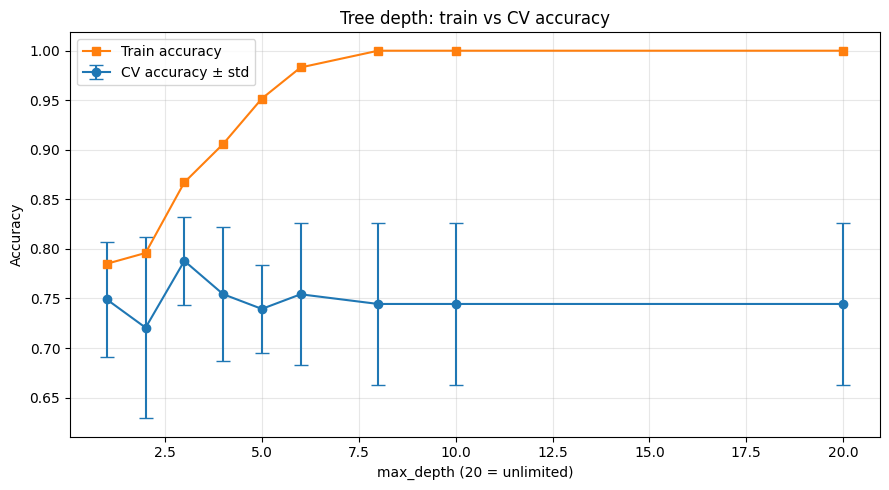

In [20]:
#3b
import matplotlib.pyplot as plt

depths_plot = [1, 2, 3, 4, 5, 6, 8, 10, 20] 
train_accs = [r["train_acc"] for r in results]
cv_accs = [r["cv_acc"] for r in results]
cv_stds = [r["cv_std"] for r in results]

depth_labels = [20 if d == "None" else int(d) for d in [r["depth"] for r in results]]

fig, ax = plt.subplots(figsize=(9, 5))
ax.errorbar(depth_labels, cv_accs, yerr=cv_stds, marker="o", label="CV accuracy ± std", capsize=5)
ax.plot(depth_labels, train_accs, marker="s", label="Train accuracy")

ax.set_xlabel("max_depth (20 = unlimited)")
ax.set_ylabel("Accuracy")
ax.set_title("Tree depth: train vs CV accuracy")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [21]:
#3d
leaf_sizes = [1, 2, 5, 10, 20, 40]
results_leaf = []

for leaf in leaf_sizes:
    model = DecisionTreeClassifier(
        criterion="entropy", max_depth=None, min_samples_leaf=leaf, random_state=SEED
    )
    scores = cross_validate(model, X_train, y_train, cv=cv,
                            scoring="accuracy", return_train_score=True)
    model.fit(X_train, y_train)
    n_leaves = model.get_n_leaves()
    
    results_leaf.append({
        "min_samples_leaf": leaf,
        "leaves": n_leaves,
        "train_acc": scores["train_score"].mean(),
        "cv_acc": scores["test_score"].mean(),
        "cv_std": scores["test_score"].std(),
    })

print(f"{'Leaf':<8} {'Leaves':<8} {'Train Acc':<12} {'CV Acc':<12} {'CV Std':<10}")
print("-" * 55)
for r in results_leaf:
    print(f"{r['min_samples_leaf']:<8} {r['leaves']:<8} {r['train_acc']:<12.4f} {r['cv_acc']:<12.4f} {r['cv_std']:<10.4f}")

Leaf     Leaves   Train Acc    CV Acc       CV Std    
-------------------------------------------------------
1        33       1.0000       0.7445       0.0816    
2        30       0.9698       0.7638       0.0516    
5        18       0.8998       0.7638       0.0440    
10       11       0.8660       0.7928       0.0496    
20       8        0.8032       0.7303       0.0946    
40       5        0.7851       0.7490       0.0576    


In [22]:
#3e
from sklearn.metrics import accuracy_score

# Chosen model: depth=3
chosen = DecisionTreeClassifier(criterion="entropy", max_depth=3, random_state=SEED)
chosen.fit(X_train, y_train)
y_pred = chosen.predict(X_test)

acc = accuracy_score(y_test, y_pred)
n_test = len(y_test)
se = np.sqrt(acc * (1 - acc) / n_test)

print(f"Test accuracy: {acc:.4f}")
print(f"Standard error: {se:.4f}")
print(f"95% CI: [{acc - 1.96*se:.4f}, {acc + 1.96*se:.4f}]")


Test accuracy: 0.8111
Standard error: 0.0413
95% CI: [0.7302, 0.8920]


In [23]:
#Task 4
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# Model 1: chosen tree (depth=3)
tree_chosen = DecisionTreeClassifier(criterion="entropy", max_depth=3, random_state=SEED)
scores_tree = cross_validate(tree_chosen, X_train, y_train, cv=cv, scoring=("accuracy", "f1"))

print("Tree (depth=3):")
print("  CV accuracy:", scores_tree["test_accuracy"].mean(), "±", scores_tree["test_accuracy"].std())
print("  CV F1:     ", scores_tree["test_f1"].mean())
print()

# Model 2: unlimited tree
tree_full = DecisionTreeClassifier(criterion="entropy", max_depth=None, random_state=SEED)
scores_full = cross_validate(tree_full, X_train, y_train, cv=cv, scoring=("accuracy", "f1"))

print("Tree (unlimited):")
print("  CV accuracy:", scores_full["test_accuracy"].mean(), "±", scores_full["test_accuracy"].std())
print("  CV F1:     ", scores_full["test_f1"].mean())
print()

# Model 3: logistic regression with pipeline
logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000))
scores_lr = cross_validate(logreg, X_train, y_train, cv=cv, scoring=("accuracy", "f1"))

print("Logistic Regression:")
print("  CV accuracy:", scores_lr["test_accuracy"].mean(), "±", scores_lr["test_accuracy"].std())
print("  CV F1:     ", scores_lr["test_f1"].mean())

Tree (depth=3):
  CV accuracy: 0.7879210220673635 ± 0.04428484768994749
  CV F1:      0.7564699458817106

Tree (unlimited):
  CV accuracy: 0.7444831591173056 ± 0.08160140218013374
  CV F1:      0.7329882978663467

Logistic Regression:
  CV accuracy: 0.821835075493612 ± 0.05635965541619488
  CV F1:      0.7911266292474624


In [24]:
#4b
tree_raw = DecisionTreeClassifier(criterion="entropy", max_depth=3, random_state=SEED)
tree_raw.fit(X_train, y_train)
preds_raw = tree_raw.predict(X_test)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

tree_scaled = DecisionTreeClassifier(criterion="entropy", max_depth=3, random_state=SEED)
tree_scaled.fit(X_train_scaled, y_train)
preds_scaled = tree_scaled.predict(X_test_scaled)

agreement = (preds_raw == preds_scaled).mean()
print(f"Agreement: {agreement:.4f}")

Agreement: 1.0000


In [25]:
#4c
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

tree_final = DecisionTreeClassifier(criterion="entropy", max_depth=3, random_state=SEED)
tree_final.fit(X_train, y_train)
tree_pred = tree_final.predict(X_test)

logreg_final = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000))
logreg_final.fit(X_train, y_train)
lr_pred = logreg_final.predict(X_test)

print("=== Tree (depth=3) ===")
print("Accuracy:", accuracy_score(y_test, tree_pred))
print("F1:      ", f1_score(y_test, tree_pred))
print("Confusion matrix:")
print(confusion_matrix(y_test, tree_pred))
print()

print("=== Logistic Regression ===")
print("Accuracy:", accuracy_score(y_test, lr_pred))
print("F1:      ", f1_score(y_test, lr_pred))
print("Confusion matrix:")
print(confusion_matrix(y_test, lr_pred))

=== Tree (depth=3) ===
Accuracy: 0.8111111111111111
F1:       0.7733333333333333
Confusion matrix:
[[44  4]
 [13 29]]

=== Logistic Regression ===
Accuracy: 0.8555555555555555
F1:       0.8433734939759037
Confusion matrix:
[[42  6]
 [ 7 35]]


Both models were fitted on the full training split and evaluated once on the test split.

**Tree (depth=3)**
- Accuracy: **0.8111**
- F1: **0.7733**
- Confusion matrix:
   [[44  4]
 [13 29]]

- True negatives: 44, false positives: 4
- False negatives: 13, true positives: 29

**Logistic Regression**
- Accuracy: **0.8556**
- F1: **0.8434**
- Confusion matrix:
  [[42  6]
 [ 7 35]]

- True negatives: 42, false positives: 6
- False negatives: 7, true positives: 35

**Observations:** Logistic regression wins on accuracy (+0.045), F1 (+0.070), and most importantly for a medical task — it has roughly **half the false negatives** (7 vs 13). False negatives mean patients with disease predicted as healthy, which is the costlier error.


### 4d Conclusion

I would use logistic regression.

CV accuracy: logreg 0.822, tree 0.788. Difference is 0.034 — small.
Test accuracy: logreg 0.856 (std error 0.037), tree 0.811 (std error 0.041). Difference is 0.044. Sum of standard errors is 0.078. Since 0.044 is smaller than 0.078, I cannot say the difference is real — it could be noise.

But F1 is better for logreg: 0.843 vs 0.773. And logreg has 7 false negatives, tree has 13. Missing a sick patient is worse than a false alarm. This matters more than the accuracy gap.

So logistic regression is the safer choice. I am moderately confident. With only 90 test patients, more data would be needed to prove the accuracy difference.